# 3. Entrenamiento y Evaluación de Modelos

Este proyecto usó datos del [**"Online Shoppers Purchasing Intention Dataset"**](https://doi.org/10.24432/C5F88Q) creado por C. Sakar y Yomi Kastro (2018), alojado en el "UCI Machine Learning Repository". El dataset original tiene una licencia [**CC BY 4.0**](https://creativecommons.org/licenses/by/4.0/legalcode). Sobre los registros originales se aplicaron transformaciones de limpieza y preprocesamiento, particionado (*train/test*) y generación de variables derivadas. El código fuente de este proyecto se distribuye bajo la **Licencia MIT** (ver archivo `LICENSE`).

## 3.0. Importación de librerías y datos

In [1]:
#Importar librerias y funciones
import joblib
import pandas as pd
import numpy as np
import shap
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from importlib.util import spec_from_file_location, module_from_spec
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate, GridSearchCV, cross_val_predict
from sklearn.metrics import precision_score, recall_score, average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve, ConfusionMatrixDisplay, confusion_matrix
#Importar modelos
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

In [2]:
#Importacion del ColumnTransformer
# 1. Le damos la ruta relativa
ruta_training = Path("../src/training.py").resolve()

# 2. Cargamos el archivo directamente en una variable de módulo
spec = spec_from_file_location("training", ruta_training)
training = module_from_spec(spec)
spec.loader.exec_module(training)

# 3. Extraemos el transformador
transformer_base = training.transformer_base

In [3]:
#Cargamos el train set
train_set = pd.read_csv("../data/train/online_shoppers_intention_processed_train.csv", sep=",", index_col=0)
#Carganos el test set
test_set = pd.read_csv("../data/test/online_shoppers_intention_processed_test.csv", sep=",", index_col=0)

In [4]:
#Separamos target de features
target = "Revenue"
X_train_set = train_set.drop(columns=[target])
y_train_set = train_set[target]
X_test_set = test_set.drop(columns=[target])
y_test_set = test_set[target]
#Comprobamos dimensiones
print("Dimensiones:")
print("train_set:", train_set.shape)
print("X_train_set:", X_train_set.shape)
print("y_train_set:", y_train_set.shape)
print("test_set:", test_set.shape)
print("X_test_set:", X_test_set.shape)
print("y_test_set:", y_test_set.shape)

Dimensiones:
train_set: (9864, 14)
X_train_set: (9864, 13)
y_train_set: (9864,)
test_set: (2466, 14)
X_test_set: (2466, 13)
y_test_set: (2466,)


## 3.1. Entendiendo el ColumnTransformer

In [5]:
transformer_base

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_scaler', ...), ('num_scaler', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features p

Hemos preparado un `ColumnTransformer` con todas las transformaciones necesarias que hemos importado de `src/training.py`:

* **log_scaler**: que incluye un `SimpleImputer` con `strategy='median'` (para este dataset no sería necesario pero lo hemos incluido por robustez de cara a futuros valores NaN), seguido por una transformación logarítmica `log1p` y un `StandarScaler`. Que se aplica a las columnas `Administrative`, `Informational`, `ProductRelated`, `Administrative_Duration`, `Informational_Duration` y `ProductRelated_Duration`. 

- **num_scaler**: que incluye un `SimpleImputer` con `strategy='median'` (para este dataset no sería necesario pero lo hemos incluido por robustez de cara a futuros valores NaN), seguido por un `StandarScaler`. Que se aplica a las columnas `ProductRelated_Ratio`, `ProductRelated_Duration_Ratio`, `SpecialDay` y `ExitRates`.

* **cat_std**: que incluye un `OneHotEncoder` con las opciones `sparse_output=False` y `handle_unknown="ignore"`. Que hemos usado para las columnas `Month` y `VisitorType`.

- **cat_TrafficType**: que se aplica unicamente a la columna `TrafficType`. Primero, se aplica `asarray` para convertir los valores numéricos a str y así asegurarnos que si en un futuro entraran datos NaN (float) no alteraran los nombres de columnas pues esta variable es de tipo int de partida. Después, se ha aplicado un `OneHotEncoder` con las opciones `sparse_output=False`, `handle_unknown="ignore"` y `min_frequency=0.01`. Esta última agrupará los canales conocidos que son poco frecuentes (< 1%) en una columna TrafficType_infrequent_sklearn para así reducir la cardinalidad de esta columna que tenía 20 grupos.

En este caso se añadió un `SimpleImputer con strategy='median'` de cara a futura puesta en producción para que cuando entren NaNs no diera error, pero habría que programar alguna forma de marcar esas predicciones suboptimas ya que el dataset no tenía valores NaN.

Veamos una prueba sobre train set:

In [12]:
#Clone: IMP, nos permite hacer copias limpias sin modificar la plantilla transformer_base
#fit_transform: IMP, nos devuelve un nuevo df transformado, sin modificar el train_set original
train_set_transform = clone(transformer_base).fit_transform(train_set)
print("Dimensiones:", train_set_transform.shape)
train_set_transform.columns

Dimensiones: (9864, 35)


Index(['Administrative', 'Informational', 'ProductRelated',
       'Administrative_Duration', 'Informational_Duration',
       'ProductRelated_Duration', 'ProductRelated_Ratio',
       'ProductRelated_Duration_Ratio', 'SpecialDay', 'ExitRates',
       'Month_August', 'Month_December', 'Month_February', 'Month_July',
       'Month_June', 'Month_March', 'Month_May', 'Month_November',
       'Month_October', 'Month_September', 'VisitorType_New_Visitor',
       'VisitorType_Other', 'VisitorType_Returning_Visitor', 'TrafficType_1',
       'TrafficType_10', 'TrafficType_11', 'TrafficType_13', 'TrafficType_2',
       'TrafficType_20', 'TrafficType_3', 'TrafficType_4', 'TrafficType_5',
       'TrafficType_6', 'TrafficType_8', 'TrafficType_infrequent_sklearn'],
      dtype='str')

In [7]:
train_set_transform.head()

,Administrative,Informational,ProductRelated,Administrative_Duration,Informational_Duration,ProductRelated_Duration,ProductRelated_Ratio,ProductRelated_Duration_Ratio,SpecialDay,ExitRates,...,TrafficType_11,TrafficType_13,TrafficType_2,TrafficType_20,TrafficType_3,TrafficType_4,TrafficType_5,TrafficType_6,TrafficType_8,TrafficType_infrequent_sklearn
4263,1.621586,-0.47956,0.600906,1.814356,-0.465251,0.609918,-0.676097,-0.720053,3.663440,-0.612923,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5905,-0.925700,-0.47956,-1.133047,-0.977627,-0.465251,-0.434055,0.674754,0.587114,-0.311499,1.159262,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9434,-0.925700,-0.47956,-1.133047,-0.977627,-0.465251,-1.069069,0.674754,0.587114,-0.311499,0.136746,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3505,0.347943,-0.47956,0.008362,1.487872,-0.465251,0.556334,-0.071769,-0.225174,3.663440,-0.118883,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2067,-0.925700,-0.47956,0.548475,-0.977627,-0.465251,0.373170,0.674754,0.587114,-0.311499,-0.873776,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Vemos que después de aplicar el transformer, pasamos a tener 35 columnas de features:

- 11 columnas numéricas transformadas

* 24 columnas categóricas pasadas a binarias (10 meses, 3 grupos de visitantes, y 11 tipos tráfico > 1% con una columna extra que agrupa canales minoritarios conocidos)

## 3.2. Estrategias de Modelado y Métricas de Evaluación

### 3.2.1. Modelos Candidatos

Tenemos que preparar un mínimo de 5 modelos supervisados diferentes, asi que nos centraremos en los siguientes modelos de clasificación:

* Regresión logística

- Random Forest (Bagging)

* XGBoost (Boosting)

- CatBoost (Boosting)

* LightGBM (Boosting)

### 3.2.2. Selección de Métricas

Vamos a elegir las siguientes métricas: 

* `Average Precision`: Al tener un dataset desbalanceado con menos compradores, esta métrica nos permite evaluar cómo de bien concentra el modelo a los compradores potenciales en los scores altos sin dejarse engañar por los verdaderos negativos. Además, resume la curva Precision-Recall mediante la suma ponderada de la precisión en cada umbral.

- `ROC-AUC`: Mide la probabilidad de que el modelo asigne un *propensity score* más alto a un comprador aleatorio que a un no comprador aleatorio. Estándar para validar la capacidad global de ordenamiento (ranking). Es decir, capacidad global de ordenar correctamente a usuarios con alta intención frente a usuarios sin intención.

* `Brier Score`: Dirigida a calibración de probabilidades principal. Mide el error cuadrático medio directo de la probabilidad y es más estable ante outliers o probabilidades bajas. Penaliza probabilidades mal calibradas o excesivamente confiadas (que distorsionen las probabilidades hacia arriba). Importante si vamos a usar el número de probabilidad como *propensity score*.

Interpretación:

- `Average Precision (AP)`: Su rango estará entre 0-1 y su línea base de azar depende de la proporción de positivos del dataset. En el caso del train set, `Revenue==1` supone un 0.154704 del conjunto, por lo que la **línea base de azar será <= 0.155** (modelo inútil con rendimiento equivalente al azar puro, ≤ 1x). Como los datos tienen esa proporción de positivos reales, por azar acertariamos ese porcentaje 15.5% veces. A partir de este umbral, podemos evaluar el rendimiento del modelo mediante su ratio con respecto a la línea base (AP modelo / 0.155), y el techo máximo posible sería 6.45x (1 / 0.155). Si conseguimos 2x (AP > 0.31) implicaría duplicar la tasa de conversión con respecto a impactar usuarios al azar.

* `ROC-AUC`: Su rango estará entre 0-1 y su línea base de azar será 0.5 (clasifica como lanzar una moneda al aire). Tipicamente:
    - **`≤ 0.5`:** Modelo inútil (rendimiento equivalente al azar puro).
    - **`> 0.5 – 0.7`:** Modelo débil.
    - **`> 0.7 – 0.8`:** Modelo aceptable / moderado.
    - **`> 0.8 – 0.9`:** Modelo bueno / muy bueno.
    - **`> 0.9`:** Modelo excelente.

- `Brier Score`: Su rango estará entre 0-1, cuanto más bajo sea el valor mejor y su línea base de azar depende también de la proporción de positivos del dataset (p), como `Brier base = p (1-p)`. En este caso del train set, `Brier base = 0.155 * (1-0.155) = 0.131`. En base a esto se puede definir un `Brier Skill Score (BSS) = 1 - [Brier modelo / Brier base]`, que puede ser más interpretable indicando:
    - **`BSS <= 0 (Brier Score >= 0.131)`:** Modelo inútil / mal calibrado.
    - **`BSS 0-1 (Brier Score 0-0.131)`:** los rangos de calibración intermedios. Por ejemplo, un BSS = 0.2 (Brier Score = 0.105) implica que el modelo reduce un 20% el error cuadrático de probabilidad frente al azar.
    - **`BSS = 1 (Brier Score = 0)`:** Límite superior / calibrado perfecto.

Priorización según las fases:

1. **Modelos Baseline**: Se priorizará el `Average Precision` para detectar aquellos que clasifican bien sin dejarse engañar por el desbalanceo, seguido por `ROC-AUC` para ver que ordenan bien a todos los rangos y no solo a los extremos, y finalmente `Brier Score` para ver la calibración pero sin descartar.

2. **Ajuste de Hiperparámetros de modelos top**: Se priorizará el `Brier Score` como métrica guía para optimizar la calibración de cara a su uso posterior como *propensity score*. Mientras que `Average Precision` y `ROC-AUC` se usaran para confirmar que el ajuste no degrade la capacidad discriminativa general del clasificador.

In [13]:
train_set.Revenue.value_counts(normalize=True)

Revenue
0    0.845296
1    0.154704
Name: proportion, dtype: float64

## 3.3. Entrenamiento

### 3.3.1. Fase 1: Modelos Baseline

a) Definimos los modelos baseline y sus métricas:

In [14]:
#1. Definimos los baseline models
##Ponemos n_jobs=1 y thread_count=1, para que no haya competencia con los crossvalidate
##Fijamos random_state = 42 por reproducibilidad
base_models = {
    "Logistic Regression": LogisticRegression(max_iter = 10000, random_state=42),
    "Random Forest":RandomForestClassifier(random_state= 42),
    "XGBoost":XGBClassifier(random_state = 42, n_jobs=1),
    "LightGBM":LGBMClassifier(random_state= 42, verbose = -100, n_jobs=1),
    "CatBoost":CatBoostClassifier(random_state= 42, verbose = False, thread_count=1, allow_writing_files=False),
}
# 2. Definimos las métricas clave
scoring = {
    "Avg_Precision": "average_precision",
    "ROC_AUC": "roc_auc",
    "Brier_Score": "neg_brier_score",
}

b) Lanzamos cada modelo clonando el transformer_base y guardamos resultados:

**Nota técnica:** Dado que `train_test_split` aplica `shuffle=True` por defecto, al definir los *folds* para `cross_validate`, `GridSearchCV` y `CalibratedClassifierCV` disponemos de dos opciones válidas:

 * **Indicar `cv=5` directamente:** *Scikit-learn* ejecutará internamente `StratifiedKFold(n_splits=5, shuffle=False)`, lo cual ya es determinista y representativo porque los datos vienen previamente mezclados del *split* inicial.

 * **Definir explícitamente `cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`:** Aunque no es estrictamente necesario al haber aplicado ya `shuffle=True` y `random_state=42` en el `train_test_split`.



In [15]:
#3. Cross validation de modelos baseline
## Definimos lista de resultados
results_baseline = []
## Evaluamos cada baseline clonando transformer_base
for model, clf in base_models.items():
    # Definimos tmp_pipe_bs
    tmp_pipe_bs = Pipeline([("preprocessor",clone(transformer_base)),("classifier",clf)])
    # Hacemos cross validation para el modelo
    tmp_cv_bs = cross_validate(tmp_pipe_bs, X_train_set, y_train_set, 
                               cv = 5, scoring=scoring, n_jobs=-1)
    # Añadir resultados
    results_baseline.append({
        "Modelo":model,
        "Avg_Precision_Mean": tmp_cv_bs["test_Avg_Precision"].mean(),
        'Avg_Precision_Std': tmp_cv_bs['test_Avg_Precision'].std(),
        "ROC_AUC_Mean": tmp_cv_bs["test_ROC_AUC"].mean(),
        "ROC_AUC_Std": tmp_cv_bs["test_ROC_AUC"].std(),
        "Brier_Score_Mean": - tmp_cv_bs["test_Brier_Score"].mean(),
        "Brier_Score_Std": tmp_cv_bs["test_Brier_Score"].std(),
    })
    #4. Tabla de resultados
df_comparativa_baseline = pd.DataFrame(results_baseline).sort_values(by="Avg_Precision_Mean", ascending=False)

In [16]:
df_comparativa_baseline

,Modelo,Avg_Precision_Mean,Avg_Precision_Std,ROC_AUC_Mean,ROC_AUC_Std,Brier_Score_Mean,Brier_Score_Std
4,CatBoost,0.353947,0.011766,0.774153,0.004800,0.115739,0.001149
3,LightGBM,0.353530,0.008679,0.772812,0.005997,0.115988,0.000996
1,Random Forest,0.342390,0.017286,0.758842,0.008812,0.117242,0.001933
0,Logistic Regression,0.341124,0.004897,0.758735,0.006629,0.116315,0.000486
2,XGBoost,0.339544,0.019046,0.758826,0.011036,0.122597,0.003450


| Modelo | Avg_Precision (CV=5; ↑ mayor es mejor) | ROC_AUC (CV=5; ↑ mayor es mejor) | Brier_Score (CV=5; ↓ menor es mejor) |
| :--- | :---: | :---: | :---: |
| **CatBoost** | 0.3539 ± 0.0118 | 0.7742 ± 0.0048 | 0.1157 ± 0.0012 |
| **LightGBM** | 0.3535 ± 0.0087 | 0.7728 ± 0.0060 | 0.1160 ± 0.0010 |
| **Random Forest** | 0.3424 ± 0.0173 | 0.7588 ± 0.0088 | 0.1172 ± 0.0019 |
| **Logistic Regression** | 0.3411 ± 0.0049 | 0.7587 ± 0.0066 | 0.1163 ± 0.0005 |
| **XGBoost** | 0.3395 ± 0.0190 | 0.7588 ± 0.0110 | 0.1226 ± 0.0035 |

En este caso tenemos dos claros ganadores: `CatBoost` y `LightGBM`. Con respecto a sus métricas:

- `Avg_Precision_Mean`, CatBoost = 0.353947 y LightGBM = 0.353530 ofrecen los mejores valores que implican más que duplicar la tasa de conversión con respecto a impactar usuarios al azar, 2.283527 veces y 2.280841 veces con respecto a la línea base (0.155), respectivamente. Además, vemos que sus desviaciones estándar son relativamente pequeñas.  

* `ROC_AUC_Mean`, también CatBoost = 0.774153 y LightGBM = 0.772812 ofrecen los mejores valores, aunque todos los modelos están por encima del 0.75 en un rango de modelo aceptable / moderado.

- `Brier_Score_Mean`, CatBoost = 0.115739 y LightGBM = 0.115988 ofrecen los mejores valores
(menores), que implican que el modelo reduce un 11.65% (BSS = 0.116496183) y un 11.46% (BSS = 0.11459542) el error cuadrático de probabilidad frente al azar, respectivamente.

Por otro lado, `Random Forest`, `Logistic Regression` y `XGBoost`, presentan valores inferiores. Así que vamos a continuar con `CatBoost` y `LightGBM` para la siguiente fase de optimización de hiperparámetros.

### 3.3.2. Fase 2: Ajuste de Hiperparámetros para Modelos Seleccionados

a) Optimización de CatBoost:

CatBoost ofrece una variedad de hiperparámetros para controlar el entrenamiento del modelo y mejorar su rendimiento. En este caso, hemos decidido explorar la siguiente rejilla de valores teniendo en mente su futuro uso para un *propensity score*:

- `depth`: Indica la profundidad de los árboles y controla la complejidad del modelo. Probaremos los valores 3 y 6. El valor `depth=3` crea árboles con 2³(8) hojas para capturar relaciones principales simples sin memorizar ruido. El valor por defecto es `depth=6` que crea 2^6 (64) hojas y permite capturar interacciones más complejas entre variables. Se han evitado profundidades mayores para reducir el grid y evitar sobreajuste (overfitting).

* `learning_rate`: Tasa de aprendizaje del algoritmo. Valores más bajos hacen que el modelo sea más robusto a sobreajuste, pero puede requerir más iteraciones.  Probaremos los valores 0.03 (suele ser el default), 0.05 y 0.1. Las tasas bajas y moderadas (0.03 y 0.05) obligan al modelo a aprender de forma gradual, lo que produce probabilidades mucho más suaves y mejor calibradas. Incluir 0.1 ofrece un punto más rápido que funciona muy bien cuando el GridSearchCV lo combina con un número bajo de árboles (100 o 250).

- `l2_leaf_reg`: Coeficiente para el término de regularización L2 del coste. Puede ser utilizado para balancear la sobre-adaptación del modelo. Probaremos los valores 1, 3, 5 y 10. `l2_leaf_reg=1` da mayor libertad si los patrones en los datos están limpios. `l2_leaf_reg=3` es el valor estándar de referencia de CatBoost. `l2_leaf_reg=5 y 10`, suavizan las predicciones cuando hay ruido en los datos de comportamiento y evitan que el modelo tenga "exceso de confianza", mejorando la calibración.

* `auto_class_weights = None`: Se mantiene en su valor por defecto ya que nos interesa que no se inflen artificialmente las probabilidades. Este parámetro suele usarse para corregir datasets desbalanceados, pero en este caso nos interesa preservar la escala probabilidad.

- `iterations`: Número de árboles a entrenar. Tenemos cuatro valores (100, 250, 500, 750), que cubren el espectro necesario para equilibrar los distintos `learning_rate`. Su valor por defecto es 1000, pero asi vamos a intentar bajar posibles sobreajustes.

En **total 96 combinaciones**, usando un CV=5 serían **480 modelos** (más 1 modelo final con la mejor combinación sobre todos los datos, haciendo 481 en total).

In [12]:
# 1. Definimos el pipeline
pipeline_catboots = Pipeline([("preprocessor",clone(transformer_base)),
                                 ("modelo",CatBoostClassifier(random_state= 42, verbose = False, thread_count=1, allow_writing_files=False)),
                                 ])
# 2. grid de parámetros
param_grid_catboots = {'modelo__depth': [3, 6],
          'modelo__learning_rate': [0.03, 0.05, 0.1],
          'modelo__l2_leaf_reg':[1, 3, 5 , 10],
          'modelo__iterations': [100, 250, 500, 750],
          }
# 3. Lanzamos GridSearchCV
catboots_grid = GridSearchCV(estimator = pipeline_catboots,
                             param_grid = param_grid_catboots,
                             scoring = scoring, #Métricas de interés
                             refit = "Brier_Score", #Métrica a optimizar
                             cv = 5, #Número de folds cross validation 
                             n_jobs = -1, #Usa todos núcleos disponibles
                             )
# 4. Entrenamiento solo con train
catboots_grid.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...bose=False))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__depth': [3, 6], 'modelo__iterations': [100, 250, ...], 'modelo__l2_leaf_reg': [1, 3, ...], 'modelo__learning_rate': [0.03, 0.05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'Avg_Precision': 'average_precision', 'Brier_Score': 'neg_brier_score', 'ROC_AUC': 'roc_auc'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'Brier_Score'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strateg

En mi ordenador ha tardado 1m36.5s

In [ ]:
# Vamos a guardar el modelo para no tener que volver a lanzarlo mas a delante
joblib.dump(catboots_grid, '../models/catboots_gridsearch_completo.joblib')

['../models/catboots_gridsearch_completo.joblib']

In [ ]:
# Cargar el objeto GridSearchCV completo desde la ruta donde lo guardaste
catboots_grid = joblib.load('../models/catboots_gridsearch_completo.joblib')

In [ ]:
#Obtenemos valores del mejor resultado
idx_best_catboots = catboots_grid.best_index_
res_catboots = catboots_grid.cv_results_
#Mostramos los resultados
print("GridSearchCV CatBoost")
print("\n1. MEJOR COMBINACIÓN (según Brier Score)")
for param, val in catboots_grid.best_params_.items():
    print(f"  {param}: {val}")

print("\n2. MÉTRICAS EN VALIDACIÓN CRUZADA (CV=5)")
print(f"  Brier Score (menor es mejor): {-res_catboots['mean_test_Brier_Score'][idx_best_catboots]:.4f} (± {res_catboots['std_test_Brier_Score'][idx_best_catboots]:.4f})")
print(f"  Average Precision (PR-AUC):   {res_catboots['mean_test_Avg_Precision'][idx_best_catboots]:.4f} (± {res_catboots['std_test_Avg_Precision'][idx_best_catboots]:.4f})")
print(f"  ROC-AUC:                      {res_catboots['mean_test_ROC_AUC'][idx_best_catboots]:.4f} (± {res_catboots['std_test_ROC_AUC'][idx_best_catboots]:.4f})")

GridSearchCV CatBoost

1. MEJOR COMBINACIÓN (según Brier Score)
  modelo__depth: 6
  modelo__iterations: 250
  modelo__l2_leaf_reg: 10
  modelo__learning_rate: 0.03

2. MÉTRICAS EN VALIDACIÓN CRUZADA (CV=5)
  Brier Score (menor es mejor): 0.1131 (± 0.0008)
  Average Precision (PR-AUC):   0.3737 (± 0.0126)
  ROC-AUC:                      0.7807 (± 0.0031)


Como podemos ver después de la optimizar los hiperparámetros hemos conseguido mejorar las 3 métricas con respecto al modelo CatBoost baseline.

b) Optimización de LightGBM:

LightGBM ofrece una variedad de hiperparámetros para controlar el entrenamiento del modelo y mejorar su rendimiento. En este caso, hemos decidido explorar la siguiente rejilla de valores teniendo en mente su futuro uso para un *propensity score* y similitud con la rejilla anterior:

- `max_depth`: limita la profundidad de árboles. Por defecto, sin límite (-1) aunque también tiene un límite por defecto de `num_leaves=31`. Cuanto más alto mayor riesgo de sobreajuste. Probaremos los valores 3 y 6, igual que antes con `depth`. El valor `max_depth=3` crea árboles con 2³(8) hojas para capturar relaciones principales simples sin memorizar ruido. El valor `max_depth=6` que crearía 2^6 (64) hojas, que se quedarán en 31 por el límite `num_leaves=31`y permite capturar interacciones más complejas entre variables.

* `learning_rate`: Tasa de aprendizaje del algoritmo. Valores más bajos hacen que el modelo sea más robusto a sobreajuste, pero puede requerir más iteraciones. Probaremos los valores 0.03, 0.05 y 0.1 (default). Las tasas bajas y moderadas (0.03 y 0.05) obligan al modelo a aprender de forma gradual, lo que produce probabilidades mucho más suaves y mejor calibradas. Incluir 0.1 ofrece un punto más rápido que funciona muy bien cuando el GridSearchCV lo combina con un número bajo de árboles (100 o 250). Mismos valores que antes.

- `reg_lambda`: Coeficiente para el término de regularización L2 del coste (default 0.0 en LightGBM). Puede ser utilizado para balancear la sobre-adaptación del modelo. Probaremos los valores 1, 3, 5 y 10. `reg_lambda=1` da mayor libertad si los patrones en los datos están limpios. `reg_lambda=3` es el valor estándar de referencia de CatBoost. `reg_lambda=5 y 10`, suavizan las predicciones cuando hay ruido en los datos de comportamiento y evitan que el modelo tenga "exceso de confianza", mejorando la calibración.

* `bagging_fraction`: Porcentaje de filas que se muestrean aleatoriamente para entrenar cada árbol. Usaremos dos valores: `bagging_fraction=0.6` y `bagging_fraction=1` (default). Así le indicamos también que prueba un muestreo aleatorio, para reducir la varianza y suavizar las probabilidades finales. Además, habrá que indicar `bagging_freq=1`, necesario para activar el remuestreo en cada iteración. 

- `feature_fraction`: Porcentaje de columnas (variables) que cada árbol puede mirar al buscar divisiones. Probaremos dos valores (0.5 y 1). `feature_fraction=0.5` obliga a usar la mitad al azar, evitando que siempre dependa de las 2 o 3 variables más fuertes. Mientras que `feature_fraction=1`(default) pasará todas las variables.

* `n_estimators`: Número de submodelos a entrenar. Tenemos cuatro valores (100, 250, 500, 750), que cubren el espectro necesario para equilibrar los distintos `learning_rate`. Su valor por defecto es 100.

- `max_bin`: Número máximo de intervalos (bins) en los que LightGBM agrupa las variables numéricas continuas para acelerar los cortes. Valores menores simplifican los cortes y actúan como regularizador suave. Probaremos dos valores `max_bin=125` y `max_bin=255`(default).

En **total 768 combinaciones**, usando un CV=5 serían **3840 modelos** (más 1 modelo final con la mejor combinación sobre todos los datos, haciendo 3841 en total).

In [23]:
# 1. Definimos el pipeline
pipeline_lightGBM = Pipeline([("preprocessor",clone(transformer_base)),
                              ("modelo",LGBMClassifier(random_state= 42, verbose = -100, n_jobs=1)),
                              ])
# 2. grid de parámetros
param_grid_lightGBM = {'modelo__max_depth': [3, 6],
          'modelo__learning_rate': [0.03, 0.05, 0.1],
          'modelo__reg_lambda':[1, 3, 5 , 10],
          'modelo__bagging_fraction': [0.6,1],
          'modelo__feature_fraction': [0.5,1],
          'modelo__n_estimators': [100, 250, 500, 750],
          'modelo__bagging_freq': [1], # sin esto, bagging_fraction no tiene efecto
          'modelo__max_bin': [125,255]
          }
# 3. Lanzamos GridSearchCV
lightGBM_grid = GridSearchCV(estimator = pipeline_lightGBM,
                             param_grid = param_grid_lightGBM,
                             scoring = scoring, #Métricas de interés
                             refit = "Brier_Score", #Métrica a optimizar
                             cv = 5, #Número de folds cross validation 
                             n_jobs = -1, #Usa todos núcleos disponibles
                             )
# 4. Entrenamiento solo con train
lightGBM_grid.fit(X_train_set, y_train_set)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...rbose=-100))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'modelo__bagging_fraction': [0.6, 1], 'modelo__bagging_freq': [1], 'modelo__feature_fraction': [0.5, 1], 'modelo__learning_rate': [0.03, 0.05, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'Avg_Precision': 'average_precision', 'Brier_Score': 'neg_brier_score', 'ROC_AUC': 'roc_auc'}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'Brier_Score'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validati

En mi ordenador ha tardado 3m40.7s

In [24]:
# Vamos a guardar el modelo para no tener que volver a lanzarlo mas a delante
joblib.dump(lightGBM_grid, '../models/lightGBM_gridsearch_completo.joblib')

['../models/lightGBM_gridsearch_completo.joblib']

In [5]:
# Cargar el objeto GridSearchCV completo desde la ruta donde lo guardaste
lightGBM_grid = joblib.load('../models/lightGBM_gridsearch_completo.joblib')

In [25]:
#Obtenemos valores del mejor resultado
idx_best_lightGBM = lightGBM_grid.best_index_
res_lightGBM = lightGBM_grid.cv_results_
#Mostramos los resultados
print("GridSearchCV lightGBM")
print("\n1. MEJOR COMBINACIÓN (según Brier Score)")
for param, val in lightGBM_grid.best_params_.items():
    print(f"  {param}: {val}")

print("\n2. MÉTRICAS EN VALIDACIÓN CRUZADA (CV=5)")
print(f"  Brier Score (menor es mejor): {-res_lightGBM['mean_test_Brier_Score'][idx_best_lightGBM]:.4f} (± {res_lightGBM['std_test_Brier_Score'][idx_best_lightGBM]:.4f})")
print(f"  Average Precision (PR-AUC):   {res_lightGBM['mean_test_Avg_Precision'][idx_best_lightGBM]:.4f} (± {res_lightGBM['std_test_Avg_Precision'][idx_best_lightGBM]:.4f})")
print(f"  ROC-AUC:                      {res_lightGBM['mean_test_ROC_AUC'][idx_best_lightGBM]:.4f} (± {res_lightGBM['std_test_ROC_AUC'][idx_best_lightGBM]:.4f})")

GridSearchCV lightGBM

1. MEJOR COMBINACIÓN (según Brier Score)
  modelo__bagging_fraction: 1
  modelo__bagging_freq: 1
  modelo__feature_fraction: 0.5
  modelo__learning_rate: 0.05
  modelo__max_bin: 255
  modelo__max_depth: 6
  modelo__n_estimators: 100
  modelo__reg_lambda: 1

2. MÉTRICAS EN VALIDACIÓN CRUZADA (CV=5)
  Brier Score (menor es mejor): 0.1123 (± 0.0008)
  Average Precision (PR-AUC):   0.3833 (± 0.0190)
  ROC-AUC:                      0.7854 (± 0.0042)


Como podemos ver después de la optimizar los hiperparámetros hemos conseguido mejorar las 3 métricas con respecto al modelo lightGBM baseline, pero también con respecto al Catboost baseline y optimizado. De manera que el **ganador es el LightGBM optimizado**.

| Modelo | Versión | Brier Score (CV=5; ↓ menor es mejor) | Average Precision (CV=5; ↑ mayor es mejor) | ROC-AUC (CV=5; ↑ mayor es mejor) |
| :--- | :--- | :---: | :---: | :---: |
| **CatBoost** | *Baseline* | 0.1157 ± 0.0012 | 0.3539 ± 0.0118 | 0.7742 ± 0.0048 |
| **CatBoost** | *Tuned* | 0.1131 ± 0.0008 | 0.3737 ± 0.0126 | 0.7807 ± 0.0031 |
| **LightGBM** | *Baseline* | 0.1160 ± 0.0010 | 0.3535 ± 0.0087 | 0.7728 ± 0.0060 |
| **LightGBM** | ***Tuned* (Ganador)** | 0.1123 ± 0.0008 | 0.3833 ± 0.0190 | 0.7854 ± 0.0042 |


### 3.3.3. Fase 3: Ajuste del Umbral de Negocio

En este caso, vamos a definir **3 cortes de interés por capacidad de campaña**. Simularemos que el departamento de marketing tiene presupuesto para impactar distintos porcentajes de los usuarios.

Usaremos predicciones Out-of-Fold (OOF) sobre `X_train_set` mediante validación cruzada (`cross_val_predict`), asegurando que cada usuario reciba una probabilidad (que usaremos como **propensity score**) predicha por un modelo que no lo vio al entrenar. A partir de esta distribución obtendremos los umbrales que marcan el corte del Top 5%, Top 15% y Top 30% de usuarios con mayor *propensity score*:

- **Audiencia VIP (Top 5%)**: Usuarios con mayores propensity scores priorizando calidad. Sus Falsos Positivos (FP, usuarios que no compraron pero navegaron de forma similar a un comprador) serán interesantes para campañas de alto coste o incentivos como cupones descuento.

* **Audiencia Estándar (Top 15%)**: Usuarios que presentan un equilibrio entre volumen y calidad. Sus FP serán interesantes para hacer un retargeting con campañas de coste medio, como anuncios dirigidos.

- **Audiencia Amplia (Top 30%)**: Un rango mayor de los usuarios priorizando volumen. Sus FP serán interesantes para retargeting mediante canales económicos de coste marginal cero,en especial canales propios, como email o notificaciones push.

Para cada una de esas audiencias se calcularán las siguientes métricas:

- `Precision`: De todos los usuarios que superan el umbral, qué proporción sí compró en esa audiencia (`TP / Total de Positivos Predichos`). Nos ayuda a medir la calidad del patrón capturado. Por ejemplo, una Precision de **0.3** indicaría que el **30%** de los usuarios seleccionados de la audiencia sí compraron.

* `Recall`: De todos los compradores reales del conjunto, qué proporción sí compró en esa audiencia (`TP / Total Positivos Reales`). Mide la Ganancia Acumulada (*Cumulative Gain*), o cobertura, es decir, cuánto comportamiento comprador estamos capturando. Por ejemplo, con un Recall de **0.3** lograríamos capturar el **30%** de todo el comportamiento comprador del train set.

- `Lift`: Mide cuántas veces supera el modelo a una selección aleatoria (`Precision / Tasa Base`, donde la proporción base de compradores en train es **0.155**). Por ejemplo, si alcanzamos un lift **3X**, significa que para esa audiencia concentramos el triple de intención de compra que el puro azar.

* `Leads_Retargeting_FP`: Usuarios que superan el umbral pero no compraron (`y == 0`). Representan nuestro público accionable, es decir, el volumen de personas a las que impactar con diferentes estrategias de retargeting.

- `Total_Predicted_Positives`: Total de usuarios que superan el umbral en esa audiencia (`TP + FP`).

* `Perc_LeadsFP_Predicted_Positives`: El porcentaje de *leads* accionables (`FP`) respecto al total de Positivos Predichos en esa audiencia (`TP + FP`). Útil para ver qué parte de la audiencia target serían *leads* accionables.

- `Perc_LeadsFP_Total_Users`: El porcentaje de *leads* accionables (`FP`) respecto al total de usuarios del conjunto train. Útil para ver qué parte del total de usuarios del conjunto train serían *leads* accionables.

In [ ]:
#definimos función de interés para calculo de métricas
def calculo_metricas_negocio(escenarios,scores_pred, y_set):
    #Calculamos tasa_base(prop TP en el set)
    tasa_base_prop_P_set = y_set.mean() #Como son 1 y 0, hacer la media es equivalente a sacar proporcion P en el set
    ## Definimos lista resultados
    resultados_metricas = []
    # Obtenemos métricas para cada umbral de la lista escenarios (tuplas nombre, umbral)
    for nombre, th in escenarios:
        #Calculos
        preds_bin = (scores_pred >= th).astype(int) #Pasamos propensity scores predichos a binaria (en base a ese umbral th)
        leads_fp = int(np.sum((y_set == 0) & (preds_bin == 1))) #Calculamos total leads (FP para esa audiencia)
        total_sel = int(np.sum(preds_bin == 1)) #Calculamos Total_Predicted_Positives
        prec = precision_score(y_set, preds_bin) #Calculamos precision score
        #Guardamos
        resultados_metricas.append({
            "Audiencia": nombre,
            "Umbral_Score": round(th, 4),
            "Precision": round(prec, 4),
            "Recall": round(recall_score(y_set, preds_bin), 4),
            "Lift (Precision / Prop_P)":round(prec / tasa_base_prop_P_set, 2),
            "Leads_Retargeting_FP": leads_fp,
            "Total_Predicted_Positives": total_sel,
            "Perc_LeadsFP_Predicted_Positives": round((leads_fp / total_sel)*100, 2),
            "Perc_LeadsFP_Total_Users": round((leads_fp / len(y_set))*100, 2),
        })
    # Convertir a DataFrame
    df_metricas = pd.DataFrame(resultados_metricas)
    # Devolver tabla resultados
    return df_metricas

In [16]:
# 1. Generamos las probabilidades OOF usando el mejor modelo con parámetros tuneados
oof_preds = cross_val_predict(
    clone(lightGBM_grid.best_estimator_), #Al usar clone, genera un pipeline limpio con ColumnTransformer y Mejores Parámetros para el modelo (sin datos train)
    X_train_set,
    y_train_set,
    cv=5,
    method="predict_proba",
    n_jobs=-1
)[:, 1] #Añadimos esto para obtener las probabilidades(propensity scores)

# 2. Calculamos los 3 umbrales congelados como percentiles: Top 5% (percentile 95%), Top 15% (percentile 85%) y Top 30% (percentile 70%)
th_broad, th_std, th_vip = np.percentile(oof_preds, [70, 85, 95])

# 3. Validamos en OOF qué métricas y volumen de no-compradores genera cada corte en train
## Definimos escenarios
escenarios = [("VIP (Top 5 %)",th_vip),("Estándar (Top 15 %)", th_std),("Amplia (Top 30 %)", th_broad)]
## Obtenemos métricas con la funcion de arriba
df_umbrales_oof = calculo_metricas_negocio(escenarios,oof_preds, y_train_set)

In [17]:
df_umbrales_oof

,Audiencia,Umbral_Score,Precision,Recall,Lift (Precision / Prop_P),Leads_Retargeting_FP,Total_Predicted_Positives,Perc_LeadsFP_Predicted_Positives,Perc_LeadsFP_Total_Users
0,VIP (Top 5 %),0.4215,0.5061,0.1638,3.27,244,494,49.39,2.47
1,Estándar (Top 15 %),0.2867,0.4000,0.3879,2.59,888,1480,60.00,9.00
2,Amplia (Top 30 %),0.2054,0.3258,0.6317,2.11,1995,2959,67.42,20.23


Con respecto a las distintas audiencias objetivo:

* **Audiencia VIP (Top 5 %)**: tiene un umbral para el propensity score de **0.4215**, lo que genera un total de **244 usuarios** como potenciales *leads* de un total de 494 positivos predichos. Los *leads* potenciales suponen un **49.39%** de los positivos predichos en la audiencia y un **2.47%** de los usuarios totales del train set. Con respecto a las otras métricas:
    - `Precision` = **0.5061**, **50.61%** de los usuarios seleccionados de la audiencia sí compraron.
    - `Recall` = **0.1638**, logramos capturar un **16.38%** de todo el comportamiento comprador del train set.
    - `Lift` = **3.27**, con esta audiencia concentramos **3.27 veces** más intención de compra que el puro azar.

* **Audiencia Estándar (Top 15 %)**: tiene un umbral para el propensity score de **0.2867**, lo que genera un total de **888 usuarios** como potenciales *leads* de un total de 1480 positivos predichos. Los *leads* potenciales suponen un **60.00%** de los positivos predichos en la audiencia y un **9.00%** de los usuarios totales del train set. Con respecto a las otras métricas:
    - `Precision` = **0.4000**, el **40.00%** de los usuarios seleccionados de la audiencia sí compraron.
    - `Recall` = **0.3879**, logramos capturar un **38.79%** de todo el comportamiento comprador del train set.
    - `Lift` = **2.59**, con esta audiencia concentramos **2.59 veces** más intención de compra que el puro azar.

* **Audiencia Amplia (Top 30 %)**: tiene un umbral para el propensity score de **0.2054**, lo que genera un total de **1995 usuarios** como potenciales *leads* de un total de 2959 positivos predichos. Los *leads* potenciales suponen un **67.42%** de los positivos predichos en la audiencia y un **20.23%** de los usuarios totales del train set. Con respecto a las otras métricas:
    - `Precision` = **0.3258**, el **32.58%** de los usuarios seleccionados de la audiencia sí compraron.
    - `Recall` = **0.6317**, logramos capturar un **63.17%** de todo el comportamiento comprador del train set.
    - `Lift` = **2.11**, con esta audiencia concentramos **2.11 veces** más intención de compra que el puro azar.

Por otro lado, vemos un comportamiento coherente con la lógica de negocio: al aumentar el tamaño de la audiencia disminuyen tanto la proporción de usuarios que sí compraron (`Precision`) como la concentración de intención de compra frente al azar (`Lift`), mientras que aumenta la cobertura total de compradores capturados (`Recall`). **Esto confirma que el modelo ordena eficazmente a los usuarios según su propensión de compra, permitiendo elegir entre campañas más rentables y selectivas (VIP) o estrategias de mayor alcance y bajo coste (Amplia).**

Además, se ha preparado un `src/training.py` que incluye código para entrenar y guardar el modelo definitivo con hiperparámetros ajustados entrenado con el input de los datos de la carpeta `data/processed` y guardando los datasets de `data/train` y `data/test`. También hemos preparado un codigo para recalcular los umbrales de negocio en caso que se quisieran probar otras audiencias objetivo usando predicciones Out-of-Fold (OOF) sobre `X_train_set` mediante validación cruzada (`cross_val_predict`). El objeto con los resultados finales de la fase de entrenamiento también se guarda en la ruta `models/final_propensity_model.joblib`, un dict que contiene **"pipeline"**(ColumnTransformer + Modelo lightGBM ajustado a los mejores hiperparámetros y entrenado con train), **thresholds** (dict con los umbrales propensity score para las 3 audiencias de negocio), **df_oof_results** (con los resultados del cálculo de umbrales sobre train) y **train_cv_metrics** (con los resultados de las métricas sobre Train CV=5).

## 3.4. Evaluación

### 3.4.1. Evaluación global modelo final (Train CV vs Test)

Ahora obtendremos las métricas del modelo final con el test set para compararlas con las anteriores obtenidas por cross validation:

In [18]:
#Ahora calculamos las métricas con el modelo final usando test
test_preds = lightGBM_grid.best_estimator_.predict_proba(X_test_set)[:, 1]

metricas_globales_test = {
    "ROC_AUC": round(roc_auc_score(y_test_set, test_preds), 4),
    "Avg_Precision": round(average_precision_score(y_test_set, test_preds), 4),
    "Brier_Score": round(brier_score_loss(y_test_set, test_preds), 4)
}

In [19]:
metricas_globales_test

{'ROC_AUC': 0.7698, 'Avg_Precision': 0.3559, 'Brier_Score': 0.1149}

Si comparamos con los resultados anteriores:

| Modelo | Versión | Set | Brier Score (↓ menor es mejor) | Average Precision (↑ mayor es mejor) | ROC-AUC (↑ mayor es mejor) |
| :--- | :--- | :---: | :---: | :---: | :---: |
| **LightGBM** | *Baseline* | Train CV=5 |0.1160 | 0.3535 | 0.7728 |
| **LightGBM** | **Tuned** | Train CV=5 |0.1123 | 0.3833 | 0.7854 |
| **LightGBM** | **Tuned** | Test |0.1149 | 0.3559 | 0.7698 |

Con respecto a las métricas:

- `Brier Score = 0.1149`: queda comprendido entre los valores del modelo baseline (`0.1160`) y el Tuned en Train CV (`0.1123`) con diferencias pequeñas siendo ligeramente peor que el Tuned en Train CV y mejor que el baseline. Esto indicaría que la calibración es adecuada y las probabilidades estimadas son fiables como *propensity score*.

* `Average Precision = 0.3559`: también queda comprendido entre el baseline (`0.3535`) y el Tuned en Train CV (`0.3833`) con mínimas diferencias siendo ligeramente inferior que el Tuned Train CV y superior que el baseline. Este valor implica más que duplicar la tasa de conversión con respecto a impactar usuarios al azar (2.3 veces con respecto a la `línea base de 0.155`, idéntica en test ya que hicimos un `stratify=target`), manteniendo una capacidad sólida para concentrar compradores en los primeros puestos del ranking.

- `ROC AUC = 0.7698`: aunque es el valor menor de las 3 evaluaciones, la diferencia frente a su correspondiente Train CV (`0.7854`) es mínima, lo que confirma que el modelo generaliza correctamente ante usuarios nunca vistos. Además, este valor entran dentro de lo que se considera un modelo aceptable / moderado, indicando que la capacidad global de ranking es adecuada.  

En conjunto, vemos que el rendimiento del modelo optimizado (`Tuned`) se mantiene estable con pequeñas variaciones al comparar las validaciones cruzadas previas (`Train CV`) y el conjunto final de test (`Test`), lo que indicaría ausencia de sobreajuste significativo y alta estabilidad del modelo final.

### 3.4.2. Evaluación de negocio (OOF Train vs Test)

a) Ahora, hay que aplicar los umbrales de negocio que calculamos previamente para las distintas audiencias sobre `X_test_set`:

In [20]:
## Reusamos la función anterior para generar métricas con test
#1.Reutilizamos la lista escenarios con los umbrales congelados de train definidos en OOF
#2.Reutilizamos test_preds en vez de oof_preds, probabilidades predichas en Test con el modelo final (propensity scores)
#3. Le damos y_test_set
df_umbrales_test = calculo_metricas_negocio(escenarios,test_preds, y_test_set)

In [21]:
df_umbrales_test

,Audiencia,Umbral_Score,Precision,Recall,Lift (Precision / Prop_P),Leads_Retargeting_FP,Total_Predicted_Positives,Perc_LeadsFP_Predicted_Positives,Perc_LeadsFP_Total_Users
0,VIP (Top 5 %),0.4215,0.4130,0.1492,2.67,81,138,58.70,3.28
1,Estándar (Top 15 %),0.2867,0.4016,0.3953,2.59,225,376,59.84,9.12
2,Amplia (Top 30 %),0.2054,0.3058,0.6204,1.97,538,775,69.42,21.82


b) Generemos una tabla comparativa con los resultados de métricas previos:

In [22]:
#Unimos con la table previa para comparar OOF (Train) vs. Test lado a lado
df_oof_comp = df_umbrales_oof.copy()
df_oof_comp.insert(0, "Set", "Train (OOF):CV=5")

df_test_comp = df_umbrales_test.copy()
df_test_comp.insert(0, "Set", "Test")

df_comparativa_negocio = (
    pd.concat([df_oof_comp, df_test_comp], ignore_index=True)
    .sort_values(by=["Umbral_Score", "Set"], ascending=[False, False])
)

In [23]:
df_comparativa_negocio

,Set,Audiencia,Umbral_Score,Precision,Recall,Lift (Precision / Prop_P),Leads_Retargeting_FP,Total_Predicted_Positives,Perc_LeadsFP_Predicted_Positives,Perc_LeadsFP_Total_Users
0,Train (OOF):CV=5,VIP (Top 5 %),0.4215,0.5061,0.1638,3.27,244,494,49.39,2.47
3,Test,VIP (Top 5 %),0.4215,0.4130,0.1492,2.67,81,138,58.70,3.28
1,Train (OOF):CV=5,Estándar (Top 15 %),0.2867,0.4000,0.3879,2.59,888,1480,60.00,9.00
4,Test,Estándar (Top 15 %),0.2867,0.4016,0.3953,2.59,225,376,59.84,9.12
2,Train (OOF):CV=5,Amplia (Top 30 %),0.2054,0.3258,0.6317,2.11,1995,2959,67.42,20.23
5,Test,Amplia (Top 30 %),0.2054,0.3058,0.6204,1.97,538,775,69.42,21.82


Como podemos ver al aplicar los umbrales para las dintintas audiencias de negocio sobre el `Test set` **las métricas mantienen su eficacia y estabilidad** al enfrentarse a datos nuevos que no ha visto nunca:

- `Audiencia VIP Top 5% (Umbral = 0.4215)`: se observa un cierta caída de la Precision (lógico debido al menor tamaño del Test set), pero se mantiene una `Precision = 0.4130` similar a los valores de la audiencia Estándar Top 15%, lo que supone un **Lift de 2.67X veces superior al azar**. Mientras que el Recall presenta valores similares al Train con un valor `Recall = 0.1492`. Conseguimos capturar **81 leads de alto valor para retargeting**, lo que supone un **58.70% de los Positivos Predichos** y un **3.28% de los usuarios del Test Set**.

* `Audiencia Estándar Top 15% (Umbral = 0.2867)`: se observan **valores muy similares de `Precision (valor = 0.4016)` y `Recall (valor = 0.3953)`**, entre sí y con su respectivo Train (OOF). Esto supone un **Lift de 2.59X veces superior al azar**. Conseguimos capturar **225 leads para retargeting**, lo que supone un **59.84% de los Positivos Predichos** y un **9.12% de los usuarios del Test Set**.

* `Audiencia Amplia Top 30% (Umbral = 0.2054)`: se observan **valores muy similares de `Precision (valor = 0.3058)` y `Recall (valor = 0.6204)`** con su respectivo Train (OOF). Esto supone un **Lift de 1.97X veces superior al azar**. Conseguimos capturar **538 leads para retargeting**, lo que supone un **69.42% de los Positivos Predichos** y un **21.82% de los usuarios del Test Set**.

c) Gráfico Curva Precision-Recall:

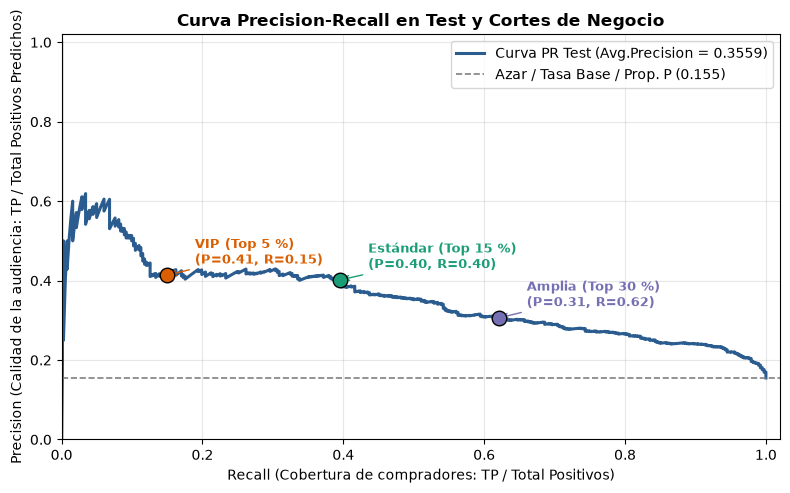

In [14]:
# 1. Calcular puntos de la curva Precision-Recall en Test
precision_curve, recall_curve, _ = precision_recall_curve(y_test_set, test_preds)
avg_precision_test = average_precision_score(y_test_set, test_preds)
tasa_base_P = y_test_set.mean() #Equivalente a proporcion Positivos Reales (P)

# 2. Preparamos el plot curva
## Definimos tamaño
fig_curve, ax1 = plt.subplots(figsize=(8, 5))

## Inicilizamos plot
ax1.plot(recall_curve, precision_curve, color="#2b5c8f", lw=2.2, label=f"Curva PR Test (Avg.Precision = {avg_precision_test:.4f})")
## Añadimos linea de la tasa base de azar
ax1.axhline(y=tasa_base_P, color="gray", linestyle="--", lw=1.2, label=f"Azar / Tasa Base / Prop. P ({tasa_base_P:.3f})")
## Marcamos las 3 audiencias objetivo
colores_cortes = ["#d95f02", "#1b9e77", "#7570b3"]
for (_, row), color in zip(df_umbrales_test.iterrows(), colores_cortes):
    ax1.scatter(row["Recall"], row["Precision"], color=color, s=110, zorder=5, edgecolor="black")
    ax1.annotate(
        f"{row['Audiencia']}\n(P={row['Precision']:.2f}, R={row['Recall']:.2f})",
        xy=(row["Recall"], row["Precision"]),
        xytext=(row["Recall"] + 0.04, row["Precision"] + 0.03),
        fontsize=9,
        fontweight="bold",
        color=color,
        arrowprops=dict(arrowstyle="->", color=color, lw=1)
    )
## Añadimos titulos
ax1.set_title("Curva Precision-Recall en Test y Cortes de Negocio", fontsize=12, fontweight="bold")
ax1.set_xlabel("Recall (Cobertura de compradores: TP / Total Positivos)", fontsize=10)
ax1.set_ylabel("Precision (Calidad de la audiencia: TP / Total Positivos Predichos)", fontsize=10)
## Ajustamos limites, grid y legenda
ax1.set_xlim([0, 1.02])
ax1.set_ylim([0, 1.02])
ax1.grid(alpha=0.3)
ax1.legend(loc="upper right", frameon=True)
#Mostrar plot
# Mostrar plot
plt.tight_layout()
plt.show()

Vemos tres zonas bien diferenciadas:

* `Zona de inestabilidad`: En esta parte izquierda de la curva el Recall es muy bajo, mientras que la Precision empieza baja y luego sube mientras va acumulando aciertos hasta llegar a unos **picos en torno a una Precision = 0.6**. Al ser un segmento reducido (por encima del Top 5%), esta zona presenta alta volatilidad y un margen de error amplio. Así que no conviene poner un corte de audiencia demasiado estrecho, pues nos interesa centrarnos en capturar FP que puedan servir como leads para retargeting, y umbrales en esta zona nos dejarían un volumen bajo de usuarios.

- `Zona de meseta central`: En esta parte central encontramos una **zona estable en torno a Precision = 0.4**. Es la zona óptima de negocio donde el modelo encuentra un grupo amplio y homogéneo de usuarios con alto parecido a compradores reales, donde sube el Recall manteniendo la Precision estable, lo que permite captar distintos volumenes de negocio sin sacrificar calidad. Esta meseta presenta un Lift 2.58X, con una propensión de compra 2.5 veces superior al azar, siendo el 60% restante de usuarios (FP) un grupo de no-compradores con un comportamiento de comprador. **Nuestros cortes del Top 5% y 15% caen en esta zona, demostrando que son puntos de corte operativos consistentes y de utilidad**.

* `Zona de caida`: En esta parte derecha, a **partir de Recall = 0.4, se observa una zona decreciente** donde aumentar Recall implica una caida progresiva de la Precision. Al ampliar la audiencia sube el volumen, pero el modelo empieza a incluir usuarios dudosos, reduciendo la calidad de la audiencia. **Nuestro corte del Top 30% cae en esta zona, por lo que puede ser interesante para retargeting de coste marginal cero**.

d) Gráficos barras comparando Test y Train (Lift y Porcentajes):

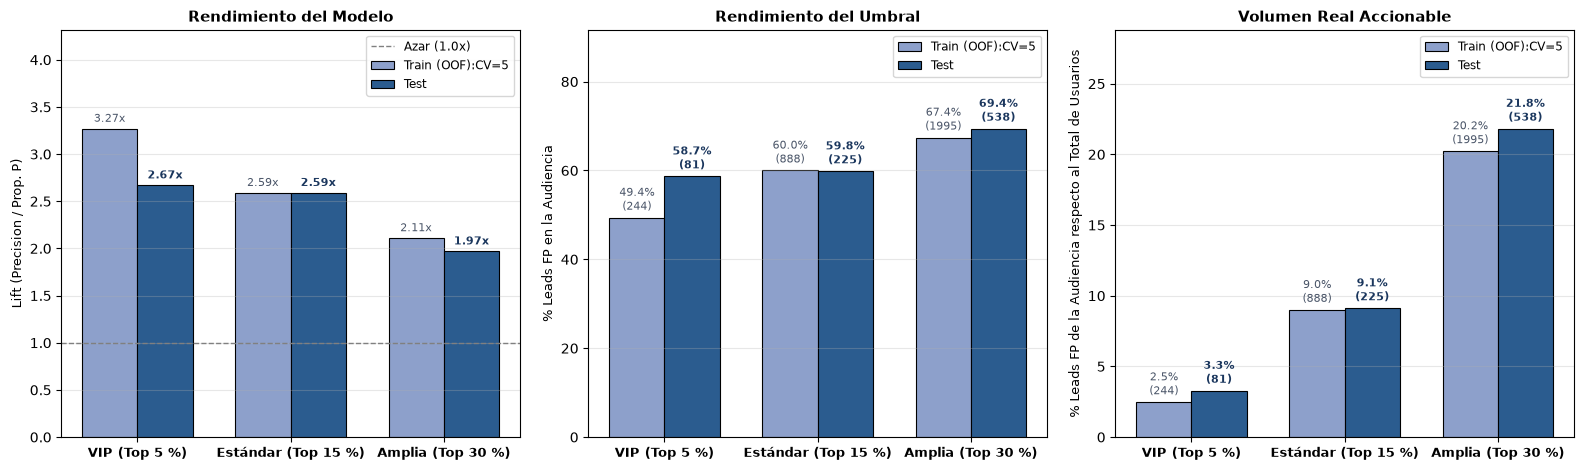

In [24]:
audiencias = df_umbrales_test["Audiencia"].tolist()
x = np.arange(len(audiencias))
width = 0.36
FP_col_name = "Leads_Retargeting_FP" 

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

configs = [
    ('Lift (Precision / Prop_P)', "Rendimiento del Modelo", "Lift (Precision / Prop. P)", False),
    ("Perc_LeadsFP_Predicted_Positives", "Rendimiento del Umbral", "% Leads FP en la Audiencia", True),
    ("Perc_LeadsFP_Total_Users", "Volumen Real Accionable", "% Leads FP de la Audiencia respecto al Total de Usuarios", True),
]

for ax, (col, titulo, ylabel, es_pct) in zip(axes, configs):
    y_oof = df_umbrales_oof[col].to_numpy(dtype=float)
    y_test = df_umbrales_test[col].to_numpy(dtype=float)

    b_oof = ax.bar(x - width/2, y_oof, width, label="Train (OOF):CV=5", color="#8da0cb", edgecolor="black", lw=0.8)
    b_test = ax.bar(x + width/2, y_test, width, label="Test", color="#2b5c8f", edgecolor="black", lw=0.8)

    lbl_oof = [f"{v:.1f}%\n({int(fp)})" if es_pct else f"{v:.2f}x" for v, fp in zip(y_oof, df_umbrales_oof[FP_col_name])]
    lbl_test = [f"{v:.1f}%\n({int(fp)})" if es_pct else f"{v:.2f}x" for v, fp in zip(y_test, df_umbrales_test[FP_col_name])]

    ax.bar_label(b_oof, labels=lbl_oof, padding=3, fontsize=8, color="#4a5568")
    ax.bar_label(b_test, labels=lbl_test, padding=3, fontsize=8, fontweight="bold", color="#1a365d")

    if col == "Lift (Precision / Prop_P)":
        ax.axhline(1.0, color="gray", linestyle="--", lw=1, label="Azar (1.0x)")

    ax.set_title(titulo, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=9.5)
    ax.set_xticks(x)
    ax.set_xticklabels(audiencias, fontsize=9.5, fontweight="bold")
    ax.set_ylim(0, max(y_oof.max(), y_test.max()) * 1.32)
    ax.grid(axis="y", alpha=0.3)
    ax.legend(loc="upper right", fontsize=8.5, frameon=True)

plt.tight_layout()
plt.show()

Lo mismo que ya hemos comentado en la tabla pero más visual.

e) Veamos las matrices de confusión para los distintos umbrales de negocio:

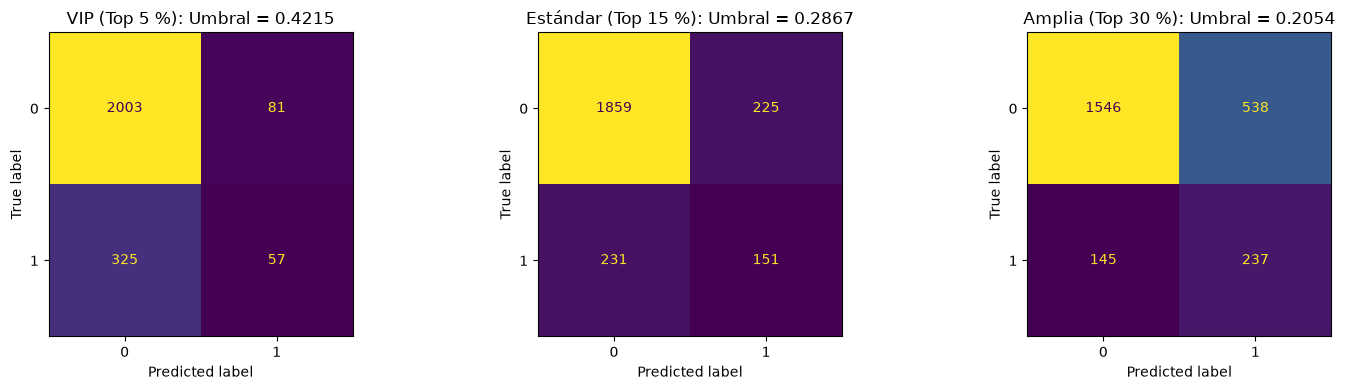

In [21]:
#Reaprovechamos escenarios y test_preds
# Configurar una figura con 3 gráficos en fila
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for i, (etiqueta,umbral) in enumerate(escenarios):
  # Convertir probabilidades a 0 o 1 según el umbral actual
  y_pred_umbral = (test_preds >= umbral).astype(int)

  # Calcular la matriz de confusión
  cm = confusion_matrix(y_test_set, y_pred_umbral)

  # Graficar la matriz en su respectivo espacio
  disp = ConfusionMatrixDisplay(confusion_matrix=cm)
  disp.plot(ax=axes[i], colorbar=False, cmap='viridis')
  axes[i].set_title(f'{etiqueta}: Umbral = {umbral:.4f}')

plt.tight_layout()
plt.show()

### 3.4.3. Explicabilidad (Feature Importance / SHAP)

Ahora, vamos a centrarnos en explorar la explicabilidad del propio modelo.

### 3.4.3.1. Feature Importance dependiente del Train Set

El modelo nos proporciona dos métricas que dependen de los datos de Train:
- `Gain`: que indica cuánto mejora realmente la capacidad predictiva del modelo cada vez que utiliza esa variable. La más importante de cara a negocio.
* `Split`: que indica cuántas veces en total el modelo ha elegido esa variable para hacer un corte en los árboles. Interesante desde un punto técnico. 

Si comparamos split vs. gain: split premia variables continuas donde el árbol hace muchos cortes finos, mientras que gain premia variables con menos cortes pero mucho más decisivos.

Para comparar ambas métricas de forma más interpretable y escaladas podemos normalizarlos como porcentajes sobre el total. Como tenemos 35 columnas, también podríamos agrupar columnas por variables relacionadas, sobretodo de cara a los OneHotEncoder.

In [56]:
# 1. Extraer el pipeline ganador
mejor_pipeline = lightGBM_grid.best_estimator_

# 2. Acceder al modelo (último paso) y al preprocesador (primer paso)
modelo_lgbm = mejor_pipeline[-1]
nombres_features = mejor_pipeline[:-1].get_feature_names_out()

# 3.Definimos grupos de variables y paleta
## Definimos un dict de agrupaciones
dict_grupos_variables = {"Administrative":["Administrative", "Administrative_Duration"],
                         "Informational":["Informational", "Informational_Duration"],
                         "ProductRelated":["ProductRelated", "ProductRelated_Duration", 
                                           "ProductRelated_Ratio", "ProductRelated_Duration_Ratio"],
                        "SpecialDay":"SpecialDay",
                        "ExitRates":"ExitRates",
                        "Month":['Month_August', 'Month_December', 'Month_February', 'Month_July',
                                 'Month_June', 'Month_March', 'Month_May', 'Month_November',
                                 'Month_October', 'Month_September'],
                        "VisitorType":['VisitorType_New_Visitor','VisitorType_Other', 'VisitorType_Returning_Visitor'],
                        "TrafficType":['TrafficType_1', 'TrafficType_10', 'TrafficType_11','TrafficType_13', 
                                       'TrafficType_2', 'TrafficType_20','TrafficType_3', 'TrafficType_4', 
                                       'TrafficType_5', 'TrafficType_6','TrafficType_8', 'TrafficType_infrequent_sklearn']
}
## Paleta de colores
dict_colores_grupos_vars = {
    "ProductRelated":  "#2b5c8f",  # Azul corporativo
    "Administrative":  "#1b9e77",  # Verde esmeralda
    "Informational":   "#66a61e",  # Verde oliva
    "Month":           "#7570b3",  # Morado
    "TrafficType":     "#386cb0",  # Azul claro
    "VisitorType":     "#e7298a",  # Magenta
    "ExitRates":       "#e6ab02",  # Ámbar
    "SpecialDay":      "#a6761d",  # Ocre
}
## Mapeamos cada columna individual a su grupo usando el diccionario
col_to_grupo = {}
for grupo, cols in dict_grupos_variables.items():
    lista_cols = [cols] if isinstance(cols, str) else cols
    for c in lista_cols:
        col_to_grupo[c] = grupo

# 4. Preparamos tabla final
## Calculamos importancia para Gain y por Split en porcentaje
imp_gain = modelo_lgbm.booster_.feature_importance(importance_type="gain")
imp_split = modelo_lgbm.booster_.feature_importance(importance_type="split")

df_model_imp = pd.DataFrame({
    "Feature": nombres_features,
    "Gain_Perc": (imp_gain / imp_gain.sum()) * 100,
    "Split_Perc": (imp_split / imp_split.sum()) * 100
}).sort_values("Gain_Perc", ascending=False).reset_index(drop=True)
## Añadimos columna "Grupo" mapeando con el dict
df_model_imp["Grupo"]=df_model_imp["Feature"].map(col_to_grupo).astype(str)

a) Veamos la tabla con las Feature Importance (sorted por Gain):

In [57]:
df_model_imp

,Feature,Gain_Perc,Split_Perc,Grupo
0,ExitRates,30.107363,16.182874,ExitRates
1,ProductRelated_Duration,17.727004,13.171263,ProductRelated
2,ProductRelated,6.705780,11.502177,ProductRelated
3,ProductRelated_Ratio,6.555858,7.111756,ProductRelated
4,Month_November,6.014327,3.519594,Month
5,Administrative_Duration,5.038861,7.583454,Administrative
6,ProductRelated_Duration_Ratio,4.423818,7.873730,ProductRelated
7,Administrative,2.859623,4.317852,Administrative
8,VisitorType_Returning_Visitor,2.764062,1.197388,VisitorType
9,Informational_Duration,1.827117,3.773585,Informational


b) Generemos unos plots centrandonos en los top 15:

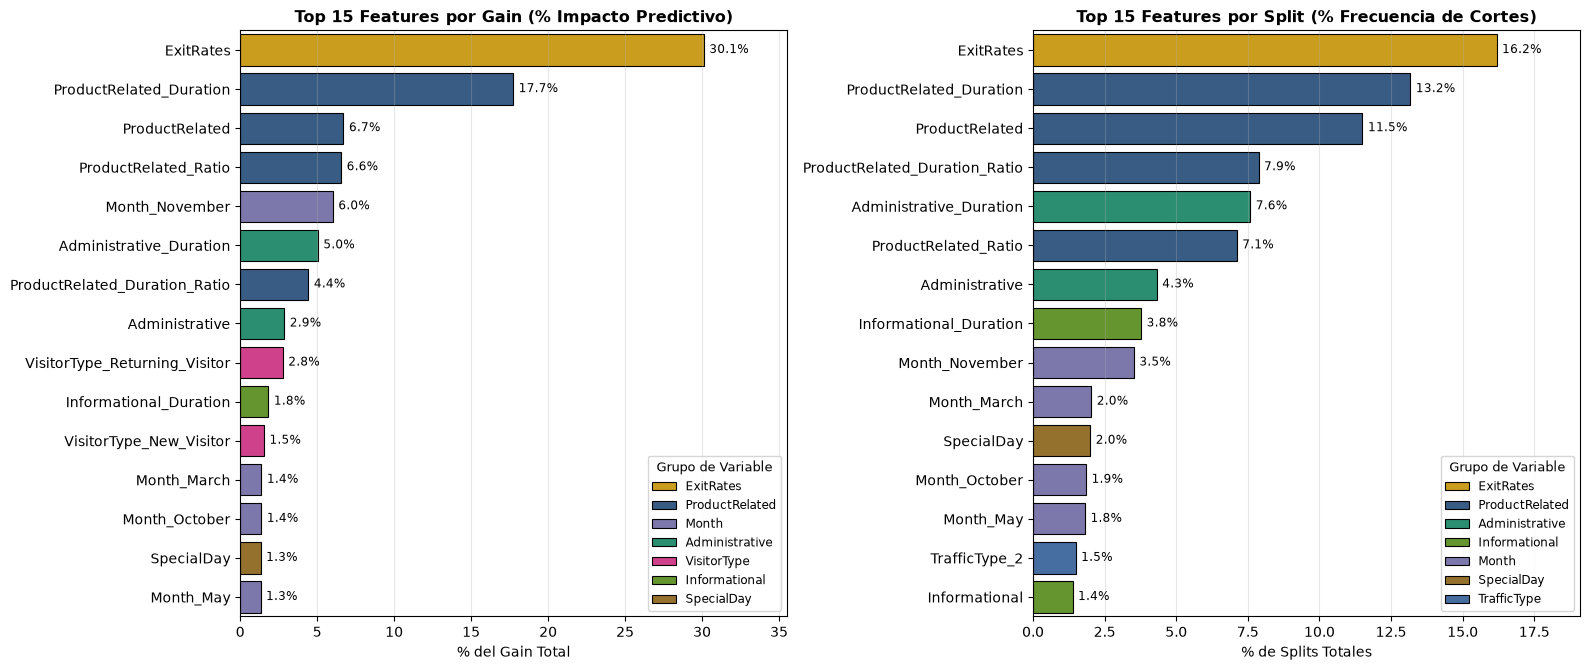

In [ ]:
# Filtramos la tablas top 15 en gain y split
top_15_gain = df_model_imp.head(15).copy()
top_15_split = df_model_imp.sort_values(by="Split_Perc", ascending=False).head(15).copy()

# Generamos la figura
## Creamos el panel doble
fig_imp, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.8))

## Panel izquierdo: Gain %
sns.barplot(
    data=top_15_gain, x="Gain_Perc", y="Feature",
    hue="Grupo", palette=dict_colores_grupos_vars, dodge=False,
    edgecolor="black", linewidth=0.8, ax=ax1
)
ax1.set_title("Top 15 Features por Gain (% Impacto Predictivo)", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("% del Gain Total", fontsize=10)
ax1.set_ylabel("")
ax1.set_xlim(0, top_15_gain["Gain_Perc"].max() * 1.18)
ax1.grid(axis="x", alpha=0.3)
ax1.legend(title="Grupo de Variable", loc="lower right", fontsize=8.5, title_fontsize=9, frameon=True)

for container in ax1.containers: #Para añadir los valores de los porcentajes
    ax1.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8.5)

## Panel derecho: Split %
sns.barplot(
    data=top_15_split, x="Split_Perc", y="Feature",
    hue="Grupo", palette=dict_colores_grupos_vars, dodge=False,
    edgecolor="black", linewidth=0.8, ax=ax2
)
ax2.set_title("Top 15 Features por Split (% Frecuencia de Cortes)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel(f"% de Splits Totales", fontsize=10)
ax2.set_ylabel("")
ax2.set_xlim(0, top_15_split["Split_Perc"].max() * 1.18)
ax2.grid(axis="x", alpha=0.3)
ax2.legend(title="Grupo de Variable", loc="lower right", fontsize=8.5, title_fontsize=9, frameon=True)

for container in ax2.containers: #Para añadir los valores de los porcentajes
    ax2.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8.5)

plt.tight_layout()
plt.show()

Vemos algunas cosas al verlas de una en una, si nos centramos en las 15 primeras para Gain:

- `ExitRates`, es **la mayoritaria tanto en Gain (30.11%) como Split (16.18%)**.

* Las del `Grupo ProductRelated` suelen estar entre **las que más porcentaje explican** (ProductRelated_Duration, ProductRelated, ProductRelated_Ratio, ProductRelated_Duration_Ratio), siendo `ProductRelated_Duration` la que **más explica dentro de este grupo tanto en Gain (17.73%) como Split (13.17%).**

- Encontramos algunas derivadas de la variable `Month` (Month_November, Month_March, Month_October, Month_May), siendo `Month_November` la que **más explica dentro de este grupo tanto en Gain (6.01%) como Split (3.52%).** También otras temporales como `SpecialDay`, con valores menores (Gain = 1.32% y Split = 2.00%).

* Así mismo, encontramos variables relacionadas con otras clasificaciones de páginas web. Las del `Grupo Administrative` (Administrative_Duration y Administrative), siendo `Administrative_Duration` la que **más explica dentro de este grupo tanto en Gain (	5.04%) como Split (7.58%).** También del `Grupo Informational`, concretamente `Informational_Duration` con valores menores (Gain = 1.83% y Split = 3.77%).

- También vemos algunas relacinadas con el `VisitorType`, como `VisitorType_Returning_Visitor` (Gain = 2.76% y Split = 1.20%) y `VisitorType_New_Visitor` (Gain = 1.54% y Split = 0.94%).

c) Ahora agrupemos los porcentajes por los grupos de variables, son 8 grupos asi que hacemos tambien el plot completo:

In [65]:
df_model_imp_grouped = df_model_imp.groupby("Grupo")[["Gain_Perc", "Split_Perc"]].sum()

In [70]:
df_model_imp_grouped.sort_values(by="Gain_Perc", ascending=False)

,Gain_Perc,Split_Perc
Grupo,,
ProductRelated,35.412460,39.658926
ExitRates,30.107363,16.182874
Month,13.100316,13.933237
Administrative,7.898484,11.901306
TrafficType,5.463442,8.998549
VisitorType,4.309794,2.177068
Informational,2.383351,5.152395
SpecialDay,1.324790,1.995646


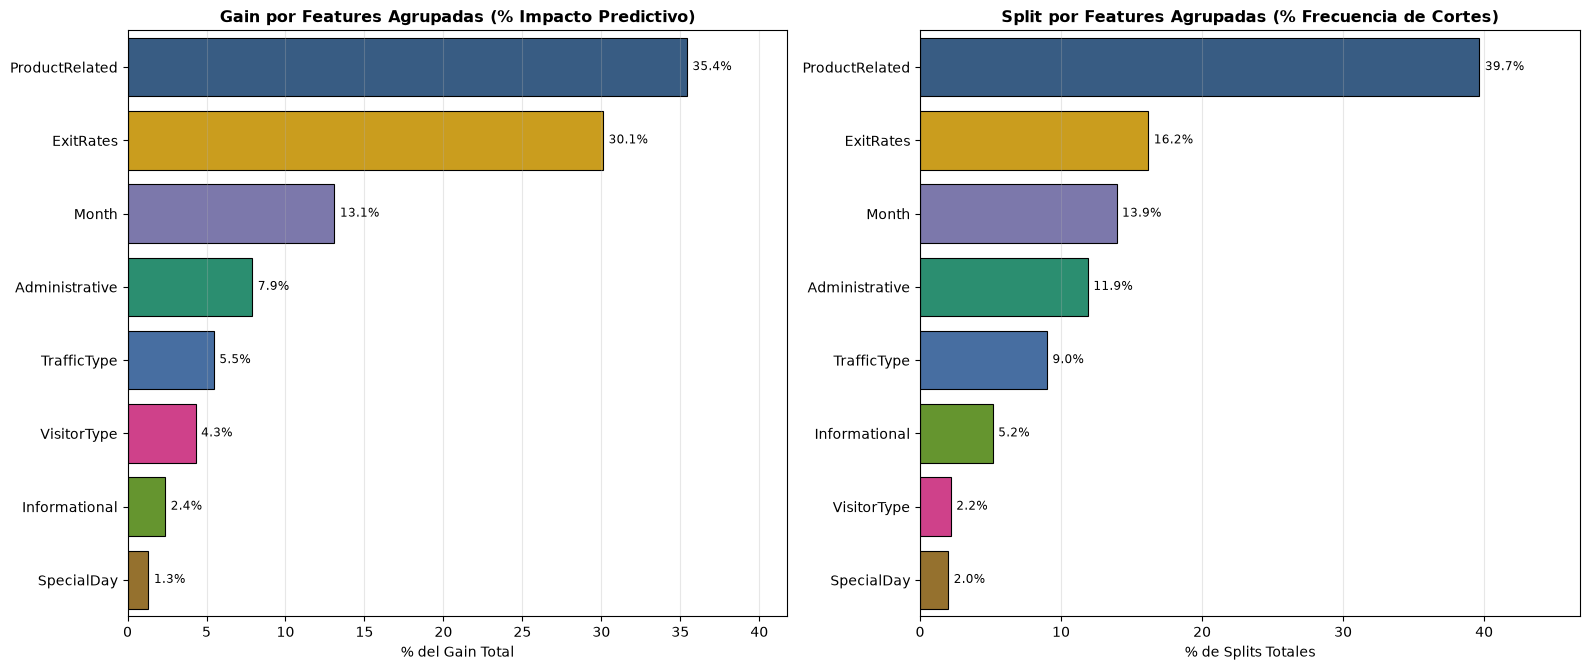

In [69]:
# Ordenamos descendentemente cada tabla
df_model_imp_grouped_gain_sorted = df_model_imp_grouped.sort_values(by="Gain_Perc", ascending=False).copy()
df_model_imp_grouped_split_sorted = df_model_imp_grouped.sort_values(by="Split_Perc", ascending=False).copy()

# Generamos la figura
## Creamos el panel doble
fig_imp_grouped, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.8))

## Panel izquierdo: Gain %
sns.barplot(
    data=df_model_imp_grouped_gain_sorted, x="Gain_Perc", y="Grupo",
    hue="Grupo", palette=dict_colores_grupos_vars, dodge=False, legend=False,
    edgecolor="black", linewidth=0.8, ax=ax1
)
ax1.set_title("Gain por Features Agrupadas (% Impacto Predictivo)", fontsize=11.5, fontweight="bold")
ax1.set_xlabel("% del Gain Total", fontsize=10)
ax1.set_ylabel("")
ax1.set_xlim(0, df_model_imp_grouped_gain_sorted["Gain_Perc"].max() * 1.18)
ax1.grid(axis="x", alpha=0.3)

for container in ax1.containers: #Para añadir los valores de los porcentajes
    ax1.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8.5)

## Panel derecho: Split %
sns.barplot(
    data=df_model_imp_grouped_split_sorted, x="Split_Perc", y="Grupo",
    hue="Grupo", palette=dict_colores_grupos_vars, dodge=False, legend=False,
    edgecolor="black", linewidth=0.8, ax=ax2
)
ax2.set_title("Split por Features Agrupadas (% Frecuencia de Cortes)", fontsize=11.5, fontweight="bold")
ax2.set_xlabel(f"% de Splits Totales", fontsize=10)
ax2.set_ylabel("")
ax2.set_xlim(0, df_model_imp_grouped_split_sorted["Split_Perc"].max() * 1.18)
ax2.grid(axis="x", alpha=0.3)

for container in ax2.containers: #Para añadir los valores de los porcentajes
    ax2.bar_label(container, fmt="%.1f%%", padding=4, fontsize=8.5)

plt.tight_layout()
plt.show()

Vemos que al agrupar features por grupos de variables, los primeros 5 grupos se mantienen en el mismo orden tanto en Gain como Split, siendo ahora el **`Grupo ProductRelated` el mayor** (Gain = 35.4% y Split = 39.7%), seguida por `ExitRates` (Gain = 30.1% y Split = 16.2%), `Month` (Gain = 13.1% y Split = 13.9%), `Administrative` (Gain = 7.9% y Split = 11.9%) y `TrafficType` (Gain = 5.5% y Split = 9.0%). Vemos que el `Grupo ProductRelated` y `ExitRates` **acumulan la mayor parte del impacto preditivo (65.5%) y frecuencia de cortes (55.9%)**. Mientras que el resto de grupos muestran porcentajes menores.

### 3.4.3.2. SHAP Summary Plot (Beeswarm) sobre el Test Set

Este gráfico va un poco más alla del feature importance del apartado previo, nos ayuda a entender qué variables importan más en nuestro modelo y en qué dirección empujan la predicción (la probabilidad de compra) para cada usuario del conjunto Test.

A diferencia de el clásico feature importance, esta representación nos muestra 4 dimensiones:

- `Eje Y - Importancia global`. Las features aparecen ordenadas de arriba abajo según su impacto medio absoluto (mean(|SHAP|)).

* `Eje X - Dirección e intensidad del impacto`. Los puntos a la derecha(+) empujan la probabilidad hacia la compra (aumentan el score del usuario), los puntos en el centro (0) indican un impacto neutro y los puntos a la izquierda (-) hacia la no compra (reducen el score del usuario). 

- `Color del punto`. Indica el valor real de la variable en cada usuario, tipicamente coloreando entre valores bajos, intermedios y altos.

* `Grosor de la nuve de puntos`. Cada punto es un usuario del Test Set, cuando muchos usuarios tienen impactos SHAP similares se apilan verticalmente formando un "enjambre" (Beeswarm) más ancho. Lo que permite ver si los efectos son homogéneos o si solo ocurren en grupos concretos de usuarios.

Además, también tiene su propio método para ordenar las features por importancia.

a) Generemos el plot con las 35 features para ver como afectan al modelo:

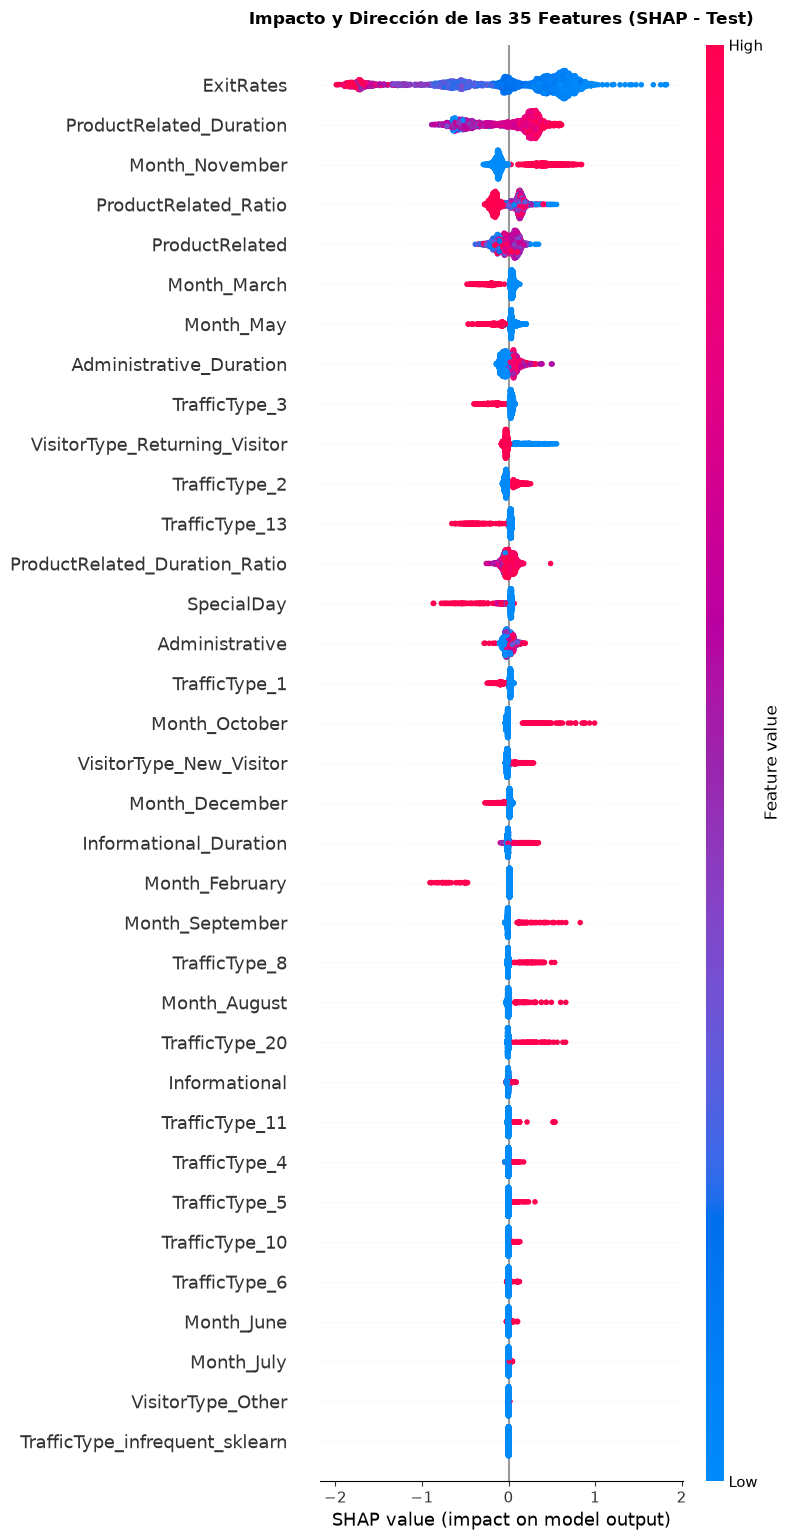

In [81]:
# 1. Separamos el modelo del Pipeline y le aplicamos su preprocesador a X_test_set
mejor_pipeline = lightGBM_grid.best_estimator_
X_test_trans = mejor_pipeline[:-1].transform(X_test_set)
modelo_lgbm = mejor_pipeline[-1]

# 2. Calculamos los valores SHAP
explainer = shap.TreeExplainer(modelo_lgbm)
shap_exp = explainer(X_test_trans)

# 3. Extraemos la explicación para la clase 1 (Compra) si viene en 3 dimensiones (filas, columnas, clases)
shap_vals_compra = shap_exp[:, :, 1] if shap_exp.values.ndim == 3 else shap_exp

#4. Veamos el plot completo para las 35 columnas
shap.summary_plot(shap_vals_compra, X_test_trans, max_display=35, show=False)
plt.title("Impacto y Dirección de las 35 Features (SHAP - Test)", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

b) Generemos un gráfico más compacto con solo las Top 15 SHAP values:

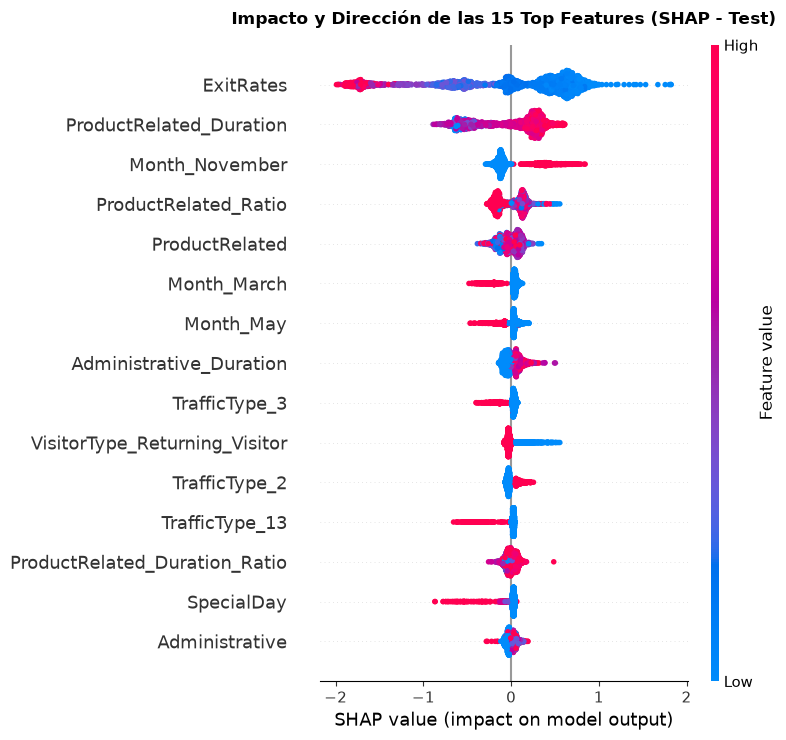

In [83]:
# Veamos el plot completo para las 15 columnas SHAP top
shap.summary_plot(shap_vals_compra, X_test_trans, max_display=15, show=False)
plt.title("Impacto y Dirección de las 15 Top Features (SHAP - Test)", fontsize=12, fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

Vemos varios patrones interesantes, por mencionar algunos casos:
- `ExitRates` tiene una relación inversa con la propensión de compra, valores menores implican mayor propensión de compra y sigue siendo la feature más importante.
* Del `Grupo ProductRelated`, se aprecian distintos patrones, `ProductRelated_Duration` tiene una relación positiva (mayor duración de la sesión en páginas relacionadas con productos mayor compra), mientras que `ProductRelated_Ratio` es negativa (cuando vemos otras categorías de páginas hay mayor compra).
- Del `Grupo Administrative`, `Administrative_Duration` tiene una relacion positiva (mayor duración de la sesión en páginas relacionadas con administración mayor compra), entre otros.
* Con respecto a la variables `Month` y `TrafficType`, vemos que hay meses con relaciones positivas y negativas para el modelo (Noviembre suele traducirse en mayor propensión de compra, mientras que Marzo y Mayo suele ser menor), y también los tipos de tráfico (Tipo 2 se traduce en mayor compra mientras los tipos 3 y 13 en menor compra).